In [1]:
import os

def arbol(ruta, nivel=0, max_nivel=3, max_items=6):
    items = sorted(os.listdir(ruta))
    for nombre in items[:max_items]:
        p = os.path.join(ruta, nombre)
        print("    " * nivel + ("📁 " if os.path.isdir(p) else "📄 ") + nombre)
        if os.path.isdir(p) and nivel + 1 < max_nivel:
            arbol(p, nivel + 1, max_nivel, max_items)
    if len(items) > max_items:
        print("    " * nivel + f"... (+{len(items) - max_items} más)")

arbol("/kaggle/input")


📁 competitions
    📁 rsna-knee-abnormality-detection
        📄 sample_submission.csv
        📄 test.csv
        📁 test_series
        📄 test_series.csv
        📄 train.csv
        📁 train_series
        ... (+1 más)
📁 datasets
    📁 bryansalva
        📁 rodilla-cnn


# Preprocesamiento de DICOM (Kaggle)

## Conceptos clave
- **Estudio**: una resonancia de rodilla de un paciente (un `StudyInstanceUID`). Tiene ~5 series.
- **Serie**: una pila de imágenes adquirida con un mismo plano y secuencia (usamos **Sagital FS**).
- **Corte (slice)**: una imagen 2D de la pila = un archivo `.dcm`. Como un pan de molde en rebanadas:
  la sagital va de **medial → centro → lateral** (mediana: 29 cortes por serie).
  - cortes mediales → menisco medial, artrosis medial
  - cortes centrales → LCA, rótula, derrame suprapatelar
  - cortes laterales → menisco lateral, artrosis lateral
- **Por qué este notebook**: una CNN necesita un tensor de **forma fija** (p. ej. `[N, 256, 256]`),
  no una carpeta de DICOM de tamaño variable. Aquí convertimos cada estudio en **un `.npy`**.
- **2D vs 2.5D**: 2D = 1 corte central `[1, H, W]`; 2.5D = N cortes repartidos de medial a lateral
  apilados como canales `[N, H, W]`.

## Diagrama de flujo del proyecto

```
 ┌─────────────────────────── FASE 1: TEXTO (Colab · rodilla.ipynb + extractor.py) ─────────────┐
 │ train.csv (4,407 reportes) ──► limpieza NFKC ──► extractor de reglas ──► 12 etiquetas 1/0/-1 │
 │                                                        │                                     │
 │                                         validación vs 56 gold (acuerdo, κ, por idioma)       │
 │                                                        │                                     │
 │ train_series.csv ──► elegibles con Sagital FS ──► selección 600 + 56 gold                    │
 │                                                        │                                     │
 │                         dataset_cnn.csv (656: train 480 / val 120 / test 56 gold)            │
 │                         series_cnn.csv  (750 series Sagital FS candidatas)                   │
 └────────────────────────────────────────────────────────┬─────────────────────────────────────┘
                                                          │ subidos como Kaggle Dataset "rodilla-cnn"
 ┌────────────── FASE 2: IMÁGENES (Kaggle · 02_preprocesamiento_dicom) ─────────────────────────┐
 │ A.1  verificar series + contar cortes ──► desempate ──► 656 series (1 por estudio)           │
 │ A.2  abrir 1 serie normal y 1 rara (320 cortes): metadatos + ver cortes ──► decidir 2D/2.5D  │
 │ A.3  función: leer ► ordenar cortes ► normalizar intensidad ► redimensionar ► elegir N       │
 │ A.4  aplicar a las 656 ──► /kaggle/working/npy/<estudio>.npy                                 │
 │ A.5  verificar + índice ──► Save Version ──► Kaggle Dataset "rodilla-npy"                    │
 └────────────────────────────────────────────────────────┬─────────────────────────────────────┘
                                                          │
 ┌────────────── FASE 3: MODELOS (Kaggle con GPU · 03_entrenamiento) ──────────────────────────┐
 │ B  Dataset PyTorch (split por estudio) + aumentos de datos                                  │
 │ C  CNN 2D/2.5D desde cero ──────────┐                                                       │
 │ D  Transfer learning (ResNet-50 /   ├──► 12 salidas sigmoide · BCEWithLogitsLoss            │
 │     EfficientNet, ImageNet) ────────┘                                                       │
 │ E  Desbalance: pos_weight / focal loss                                                      │
 └────────────────────────────────────────────────────────┬────────────────────────────────────┘
                                                          │
 ┌────────────── FASE 4: EVALUACIÓN E INFORME ──  ─────────────────────────────────────────────┐
 │ F  Evaluación en 56 gold: AUC macro + AUC por etiqueta (IC bootstrap) + P/R/F1 con umbral   │
 │ G  Ablación (≥2 factores): manejo del -1 · BCE vs focal · Sagital vs Coronal · backbone     │
 │ H  Grad-CAM (≥3 hallazgos) ──► ¿mira la anatomía correcta?                                  │
 │ I  Discusión de sesgos (idioma, centro, protocolo alemán) ──► informe NeurIPS + README      │
 └─────────────────────────────────────────────────────────────────────────────────────────────┘
```

## en detalle (este notebook)

| Paso | Qué hacemos | Resultado | 
|---|---|---|
| A | Conectar competencia + dataset `rodilla-cnn`, ubicar rutas reales | `DATA`, `MIO` |
| A.1 | Cargar `dataset_cnn.csv` y `series_cnn.csv` | 656 estudios, 750 series | 
| A.2 | ¿Existen las series? ¿Cuántos cortes tienen? | 750/750 existen; mediana 29 (24–32) |
| A.3 | Revisar la cola larga | 22 series raras (7 × 144, 15 × 320), todas únicas en su estudio |
| A.4 | Desempate: en estudios con 2–3 candidatas, la de más cortes | 656 series |
| A.5 | Abrir DICOM: metadatos (tamaño, espaciado, posición) + visualizar cortes | Decisión 2D / 2.5D y qué hacer con las de 144/320 |
| A.6 | Función de preprocesamiento, probada en 5 series | `preprocesar(serie) → array [N, H, W]` |
| A.7 | Correr las 656 series | `npy/<estudio>.npy` |
| A.8 | Verificar formas/valores + guardar índice + Save Version | Dataset `rodilla-npy` |



PASO A

In [2]:
from pathlib import Path
import pandas as pd

DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
MIO  = Path("/kaggle/input/datasets/bryansalva/rodilla-cnn")

OUT  = Path("/kaggle/working")

print("Competencia:", sorted(p.name for p in DATA.iterdir()))
print("Mi dataset: ", sorted(p.name for p in MIO.iterdir()))

dataset_cnn = pd.read_csv(MIO / "dataset_cnn.csv")
series_cnn  = pd.read_csv(MIO / "series_cnn.csv")
print(dataset_cnn.shape, series_cnn.shape)
print(dataset_cnn["split"].value_counts())

Competencia: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']
Mi dataset:  ['dataset_cnn.csv', 'series_cnn.csv']
(656, 17) (750, 3)
split
train    480
val      120
test      56
Name: count, dtype: int64


In [3]:
# ¿Existen las 750 series y cuántos cortes tiene cada una?
def carpeta_serie(fila):
    return DATA / "train_series" / fila.StudyInstanceUID / fila.SeriesInstanceUID

series_cnn["existe"]   = [carpeta_serie(f).is_dir() for f in series_cnn.itertuples()]
series_cnn["n_cortes"] = [len(list(carpeta_serie(f).glob("*.dcm"))) if f.existe else 0
                          for f in series_cnn.itertuples()]

print("Series que no existen:", (~series_cnn["existe"]).sum(), "de", len(series_cnn))
print("\nCortes por serie:")
print(series_cnn["n_cortes"].describe().round(1))
print("\nSeries con menos de 15 cortes:", (series_cnn["n_cortes"] < 15).sum())


Series que no existen: 0 de 750

Cortes por serie:
count    750.0
mean      35.0
std       42.7
min       15.0
25%       24.0
50%       29.0
75%       32.0
max      320.0
Name: n_cortes, dtype: float64

Series con menos de 15 cortes: 0


Series con más de 60 cortes: 22 de 750

Sus números de cortes:
n_cortes
144     7
320    15
Name: count, dtype: int64

n_candidatas de esas series (1 = única Sagital FS del estudio):
n_candidatas
1    22
Name: count, dtype: int64


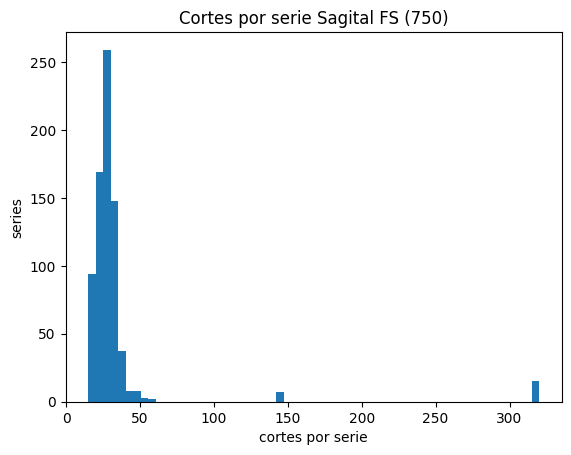

In [4]:
# 10.1c — Cola larga: series con muchos cortes
import matplotlib.pyplot as plt

largas = series_cnn[series_cnn["n_cortes"] > 60]
print("Series con más de 60 cortes:", len(largas), "de", len(series_cnn))
print("\nSus números de cortes:")
print(largas["n_cortes"].value_counts().sort_index())
print("\nn_candidatas de esas series (1 = única Sagital FS del estudio):")
print(largas["n_candidatas"].value_counts())

series_cnn["n_cortes"].plot(kind="hist", bins=60)
plt.xlabel("cortes por serie"); plt.ylabel("series")
plt.title("Cortes por serie Sagital FS (750)")
plt.show()


Necesitamos un tensor fijo para la entrada, es decir un nuemero de corte fijo para todos los .dicom de todas las series,
como vemos en la grafica notamos que la mayoria esta entre 20 y 40 aprox.

In [5]:
#  Desempate: una serie por estudio (la de más cortes; empate exacto → menor SeriesInstanceUID)
elegidas = (series_cnn
            .sort_values(["StudyInstanceUID", "n_cortes", "SeriesInstanceUID"],
                         ascending=[True, False, True])
            .drop_duplicates("StudyInstanceUID", keep="first")
            .reset_index(drop=True))

assert len(elegidas) == 656
assert set(elegidas["StudyInstanceUID"]) == set(dataset_cnn["StudyInstanceUID"])
print("Series elegidas:", len(elegidas))

# ¿Cómo eran los empates?
multi = (series_cnn[series_cnn["n_candidatas"] > 1]
         .sort_values("n_cortes", ascending=False)
         .groupby("StudyInstanceUID")["n_cortes"].apply(list))
print("Estudios con varias candidatas:", len(multi))
print("Empates exactos en nº de cortes:", multi.apply(lambda l: l[0] == l[1]).sum())
print("\nEjemplos (cortes de cada candidata, la primera es la elegida):")
print(multi.head(8).to_string())

# Guardar la selección con el split pegado
elegidas = elegidas.merge(dataset_cnn[["StudyInstanceUID", "split"]], on="StudyInstanceUID")
elegidas.to_csv(OUT / "series_elegidas.csv", index=False)
print("\nCortes de las 656 elegidas:")
print(elegidas["n_cortes"].describe().round(1))
print(elegidas.groupby("split")["n_cortes"].median())


Series elegidas: 656
Estudios con varias candidatas: 93
Empates exactos en nº de cortes: 87

Ejemplos (cortes de cada candidata, la primera es la elegida):
StudyInstanceUID
1.2.826.0.1.3680043.8.498.10096063158753121251217031021181036863        [28, 28]
1.2.826.0.1.3680043.8.498.10147717839726734017869499799005084725    [30, 30, 30]
1.2.826.0.1.3680043.8.498.10271567891603078238024189515805908561        [24, 24]
1.2.826.0.1.3680043.8.498.10284263494252700630857173843779724077        [24, 24]
1.2.826.0.1.3680043.8.498.10541029960718591409318399557079055927        [17, 15]
1.2.826.0.1.3680043.8.498.10599128554628698518723223547497007137        [28, 28]
1.2.826.0.1.3680043.8.498.10994854354532517072359864903910225174        [21, 21]
1.2.826.0.1.3680043.8.498.11218351123386367961865331646414911627        [20, 20]

Cortes de las 656 elegidas:
count    656.0
mean      36.6
std       45.4
min       15.0
25%       24.0
50%       29.0
75%       33.0
max      320.0
Name: n_cortes, dtype: float64

* Tenemos una serie por estudio para todos los 656 elegidos.
* notamos que 87 de 93 son empates exactos, solo en 6 de los estudios la regla " de mas cortes " decidio algo como verdad como [17, 15] En los otros 87, la serie la eligió el desempate por SeriesInstanceUID, que es un número de identificación sin significado médico.

Conclusión: la selección actual sirve como provisional, pero antes de fijarla vale la pena mirar las cabeceras de esos 93 estudios.

In [6]:
# Metadatos DICOM (solo cabecera, sin píxeles) de las series de estudios con varias candidatas
import pydicom
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)

def cabecera(fila):
    primer = sorted(carpeta_serie(fila).glob("*.dcm"))[0]
    d = pydicom.dcmread(primer, stop_before_pixels=True)
    g = lambda k: d.get(k, None)
    return {"SerieN":      g("SeriesNumber"),       # orden de la serie dentro del examen
            "Descripcion": g("SeriesDescription"),  # nombre que puso el técnico (p. ej. "PD FS SAG")
            "Tipo":        "\\".join(g("ImageType") or []),  # ORIGINAL (adquirida) vs DERIVED (reconstruida)
            "TE":          g("EchoTime"),           # TE bajo (~30 ms) = DP ; TE alto (>60 ms) = T2
            "TR":          g("RepetitionTime"),
            "Grosor":      g("SliceThickness"),     # mm por corte
            "Pixel":       str(g("PixelSpacing")),  # mm por píxel
            "Filas":       g("Rows"), "Cols": g("Columns")}

multi_df = series_cnn[series_cnn["n_candidatas"] > 1].copy()
multi_df = multi_df.join(pd.DataFrame([cabecera(f) for f in multi_df.itertuples()], index=multi_df.index))

print("¿Qué % de las series trae cada campo?")
print(multi_df[["SerieN", "Descripcion", "Tipo", "TE", "TR", "Grosor", "Pixel"]].notna().mean().round(2))

print("\nPrimeros 6 estudios (agrupados):")
cols = ["n_cortes", "SerieN", "Descripcion", "Tipo", "TE", "TR", "Grosor", "Pixel", "Filas", "Cols"]
print(multi_df.sort_values(["StudyInstanceUID", "SerieN"]).head(13)[["StudyInstanceUID"] + cols]
      .assign(StudyInstanceUID=lambda x: x.StudyInstanceUID.str[-6:]).to_string(index=False))


¿Qué % de las series trae cada campo?
SerieN         1.00
Descripcion    0.97
Tipo           1.00
TE             0.39
TR             0.39
Grosor         1.00
Pixel          1.00
dtype: float64

Primeros 6 estudios (agrupados):
StudyInstanceUID  n_cortes  SerieN      Descripcion                   Tipo     TE     TR  Grosor                Pixel  Filas  Cols
          036863        28       4 DummySeriesDesc! ORIGINAL\PRIMARY\OTHER 66.312 5498.0     3.0     [0.1465, 0.1465]   1024  1024
          036863        28       5 DummySeriesDesc! ORIGINAL\PRIMARY\OTHER 28.224 2287.0     3.0     [0.1465, 0.1465]   1024  1024
          084725        30       3 DummySeriesDesc! ORIGINAL\PRIMARY\OTHER 29.028 2543.0     3.0     [0.1367, 0.1367]   1024  1024
          084725        30       4 DummySeriesDesc! ORIGINAL\PRIMARY\OTHER 74.368 4345.0     3.0     [0.1367, 0.1367]   1024  1024
          084725        30   40004 DummySeriesDesc! ORIGINAL\PRIMARY\OTHER 74.368 4345.0     3.0     [0.1367, 0.1367] 

### Interpretación  — Metadatos DICOM de las candidatas empatadas

**Los empates no son repeticiones: son dos contrastes distintos de la misma sagital.**

| Estudio | Serie A | Serie B |
|---|---|---|
| 036863 | TE 66 ms -> **T2** | TE 28 ms -> **DP** |
| 908561 | "SG **PD** FatSat" | "SG **T2W** FS" |
| 724077 | "SG **PD** FatSat" | "SG **T2W** FS" |
| 055927 | "Sag **PD** frFSE" | "Sag **T2W** frFSE FS" |
| 007137 | TE 68 -> **T2** | TE 30 -> **DP** |

Estos centros adquieren dos sagitales sensibles al líquido con la misma geometría (por eso tienen igual número de cortes):

- **DP FS** (densidad protónica, TE corto ≈ 30 ms): más señal y detalle anatómico; es la secuencia de referencia
  para **meniscos, ligamentos, cartílago y edema óseo**.
- **T2 FS** (TE largo ≈ 70 ms): el líquido brilla mucho; muy buena para **derrame, quistes y edema**, pero con menos
  detalle de estructuras finas.

**Consecuencia:** el desempate por `SeriesInstanceUID` mezclaba DP y T2 al azar → ruido innecesario para la CNN
(la misma rodilla se vería distinta solo por el contraste).


**Otros hallazgos:**
- Estudio 084725 (3 candidatas): las series **4 y 40004** son idénticas (mismo TE, TR y geometría) → 40004 parece
  una **copia** (convención de reconstrucción/reenvío). Preferir la original (número de serie menor).
- **Resolución muy variable entre centros:** matrices de 1024², 640² y 512²; píxel de 0.14 a 0.35 mm; grosor de 3 a 5 mm
  → habrá que **redimensionar** en el preprocesamiento (10.3).
- `GDC` en `ImageType` indica equipos **GE**; las series `Dummy…` son de otro fabricante → el protocolo depende del
  centro y del fabricante (útil para la discusión de sesgos, req. 7).
- 055927: "Sag PD frFSE" **no dice FS** en la descripción, aunque el CSV la marca como Fat_Suppression = 1 →
  posible pequeño error de etiquetado del CSV.

**Propuesta de desempate v2:** preferir **DP FS** → si hay varias (o no se sabe el contraste), la de
**más cortes** → si siguen empatadas, el **menor número de serie**.
Se prefiere DP porque 9 de las 12 etiquetas son estructurales (meniscos, ligamentos, artrosis, contusión, fractura).


In [7]:
#  ¿DP o T2? Contraste de las 750 series (TE si existe; si no, la descripción)
cab_all = pd.DataFrame([cabecera(f) for f in series_cnn.itertuples()], index=series_cnn.index)
series_cnn = series_cnn.drop(columns=cab_all.columns, errors="ignore").join(cab_all)

def contraste(f):
    desc = str(f.Descripcion).upper()                   # 1º el nombre de la serie (lo escribió el centro)
    if "PD" in desc or "DP" in desc: return "DP"
    if "T2" in desc:                 return "T2"
    if pd.notna(f.TE):                                  # 2º el TE, solo si la descripción no lo dice
        return "DP" if float(f.TE) < 45 else "T2"
    return "?"


series_cnn["contraste"] = [contraste(f) for f in series_cnn.itertuples()]
series_cnn["multi"] = series_cnn["n_candidatas"] > 1

print("Contraste en las 750 series:")
print(series_cnn["contraste"].value_counts())
print("\nEstudios con 1 candidata vs con varias:")
print(pd.crosstab(series_cnn["contraste"], series_cnn["multi"].map({False: "única", True: "varias"})))
print("\nTE por contraste (ms):")
print(series_cnn.groupby("contraste")["TE"].apply(lambda s: pd.to_numeric(s).describe()[["count", "min", "50%", "max"]]).unstack().round(1))
print("\nDescripciones de las '?' (top 10):")
print(series_cnn.loc[series_cnn.contraste == "?", "Descripcion"].value_counts().head(10))
# ¿En cuántas series la descripción y el TE no coinciden?
te_dice = pd.to_numeric(series_cnn["TE"]).apply(lambda t: None if pd.isna(t) else ("DP" if t < 45 else "T2"))
desacuerdo = te_dice.notna() & (te_dice != series_cnn["contraste"])
print("\nDescripción vs TE en desacuerdo:", desacuerdo.sum())
print(series_cnn.loc[desacuerdo, ["TE", "Descripcion", "contraste"]].to_string(index=False))


Contraste en las 750 series:
contraste
DP    580
T2    170
Name: count, dtype: int64

Estudios con 1 candidata vs con varias:
multi      varias  única
contraste               
DP             96    484
T2             91     79

TE por contraste (ms):
           count   min   50%   max
contraste                         
DP         523.0  12.0  32.0  44.6
T2         111.0  29.8  66.2  84.1

Descripciones de las '?' (top 10):
Series([], Name: count, dtype: int64)

Descripción vs TE en desacuerdo: 2
    TE           Descripcion contraste
29.784         Sag T2 FS FSE        T2
44.672 Sag T2 FSE FS_sm_AIRS        T2


Series con TE entre 38 y 55 ms: 162
  TE          TR                  Descripcion contraste
39.0  900.000000      pd_spc_rst_fs_sag_iso R        DP
39.0  900.000000      pd_spc_rst_fs_sag_iso R        DP
39.0 2550.000000 int_tse_sag_320_p3_s2_fs_DRB        DP
39.0 3540.000000             pd_tse_fs_sag_p2        DP
39.0  900.000000      pd_spc_rst_fs_sag_iso R        DP
39.0 2550.000000 int_tse_sag_320_p3_s2_fs_DRB        DP
39.0  900.000000      pd_spc_rst_fs_sag_iso R        DP
39.0  900.000000      pd_spc_rst_fs_sag_iso R        DP
39.0 2550.000000 int_tse_sag_320_p3_s2_fs_DRB        DP
39.0  900.000000      pd_spc_rst_fs_sag_iso L        DP
39.0  900.000000      pd_spc_rst_fs_sag_iso L        DP
39.2 2439.000000             R- Sag PD FSE FS        DP
39.2 2572.000000             L- Sag PD FSE FS        DP
39.3 3903.000000                Sag PD FSE FS        DP
39.4 3734.000000                Sag PD FSE FS        DP
39.4 2900.000000                Sag PD FSE FS        DP
39.4 2766.00

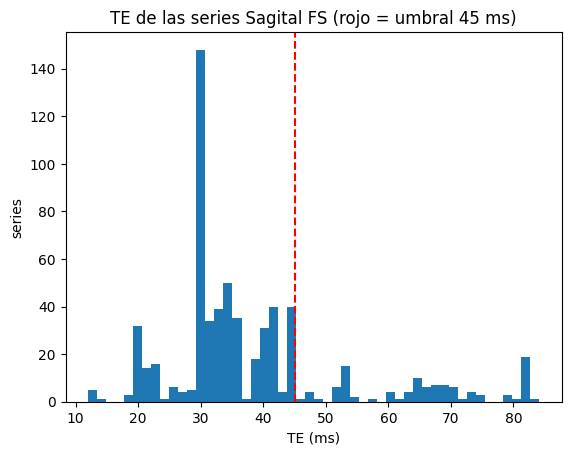


Estudios cuya serie cambió respecto a la v1: 50

Contraste de las 656 elegidas, por split:
contraste   DP  T2  All
split                  
test        50   6   56
train      423  57  480
val         98  22  120
All        571  85  656
contraste    DP    T2
split                
test       0.89  0.11
train      0.88  0.12
val        0.82  0.18


In [8]:
# (a) Series con TE en la zona dudosa  (b) Desempate v2: DP > más cortes > menor nº de serie
te = pd.to_numeric(series_cnn["TE"])
print("Series con TE entre 38 y 55 ms:", te.between(38, 55).sum())
print(series_cnn.loc[te.between(38, 55), ["TE", "TR", "Descripcion", "contraste"]]
      .assign(TE=lambda x: pd.to_numeric(x.TE).round(1))
      .sort_values("TE").to_string(index=False))

te.plot(kind="hist", bins=50); plt.axvline(45, color="red", ls="--")
plt.xlabel("TE (ms)"); plt.ylabel("series"); plt.title("TE de las series Sagital FS (rojo = umbral 45 ms)")
plt.show()

# (b) Desempate v2
series_cnn["pref"]   = series_cnn["contraste"].map({"DP": 0, "T2": 1})
series_cnn["SerieN"] = pd.to_numeric(series_cnn["SerieN"])
elegidas_v2 = (series_cnn
               .sort_values(["StudyInstanceUID", "pref", "n_cortes", "SerieN"],
                            ascending=[True, True, False, True])
               .drop_duplicates("StudyInstanceUID", keep="first")
               .merge(dataset_cnn[["StudyInstanceUID", "split"]], on="StudyInstanceUID")
               .reset_index(drop=True))
assert len(elegidas_v2) == 656

cambio = (elegidas_v2.set_index("StudyInstanceUID")["SeriesInstanceUID"]
          != elegidas.set_index("StudyInstanceUID")["SeriesInstanceUID"])
print("\nEstudios cuya serie cambió respecto a la v1:", cambio.sum())
print("\nContraste de las 656 elegidas, por split:")
print(pd.crosstab(elegidas_v2["split"], elegidas_v2["contraste"], margins=True))
print(pd.crosstab(elegidas_v2["split"], elegidas_v2["contraste"], normalize="index").round(2))

cols = ["StudyInstanceUID", "SeriesInstanceUID", "split", "contraste", "n_cortes",
        "SerieN", "TE", "Grosor", "Pixel", "Filas", "Cols"]
elegidas_v2[cols].to_csv(OUT / "series_elegidas.csv", index=False)


### Interpretación  — Contraste  y selección final

**Corrección aplicada:** `contraste()` usa primero la **descripción** y solo recurre al TE si está anonimizada.
- Solo **2 series** tenían la descripción y el TE en desacuerdo, y las dos ahora son T2 por descripción:
  `Sag T2 FSE FS_sm_AIRS` (TE 44.7) y `Sag T2 FS FSE` (TE 29.8, un TE atípicamente bajo para un T2;
  posible error del centro al nombrarla, irrelevante por ser 1 serie).
- 750 series: **580 DP / 170 T2**, ninguna sin clasificar.

**Selección final (desempate v2: DP → más cortes → menor nº de serie):**

| split | DP | T2 | % DP |
|---|---|---|---|
| train | 423 | 57 | 88 % |
| val | 98 | 22 | 82 % |
| test (gold) | 50 | 6 | 89 % |
| **total** | **571** | **85** | **87 %** |

- Cambiaron **50 de los 93** estudios respecto a la v1 (la v1 había elegido T2 al azar en esos casos).
- La proporción DP/T2 es similar entre splits → **el contraste no introduce diferencias entre train y los gold**.
- Los 85 estudios T2 son de centros que no adquieren DP sagital: se conservan y el contraste queda como variable
  a reportar (posible análisis por subgrupo).

### Resumen 
| Decisión | Valor |
|---|---|
| Series candidatas | 750, todas existen en Kaggle |
| Cortes por serie | mediana 29 (24–32); 22 series atípicas de 144/320 cortes (probable 3D isotrópica) |
| Regla de desempate | **DP FS > más cortes > menor SeriesNumber** |
| Resultado | **656 series** (una por estudio) → `series_elegidas.csv` |
| Pendiente para 10.2–10.3 | lateralidad (R/L), resolución variable entre centros, series 3D |



# abriendo las imagenes dicom

Manufacturer               SIEMENS
Laterality                 R
BodyPartExamined           KNEE
SeriesDescription          RT_pd_tse_fs_sag
PhotometricInterpretation  MONOCHROME2
BitsStored                 12
RescaleSlope               None
RescaleIntercept           None
Orientación (filas, cols)  [ 0.08  1.   -0.   -0.11  0.01 -0.99]

Posición del 1er y último corte (mm): 31.5 → 132.3
Distancia entre cortes (mm): [3.6]

Volumen: (29, 640, 640) | min 0.0 | p50 48.0 | p99 368.0 | max 960.0


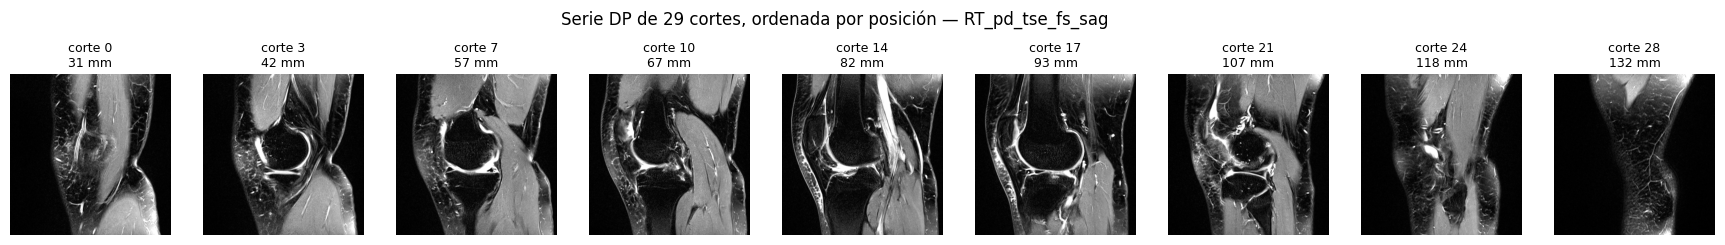

In [9]:
#  Leer UNA serie completa (DP típica de 29 cortes) y ordenarla anatómicamente
import numpy as np

def leer_serie(fila):
    cortes = [pydicom.dcmread(a) for a in carpeta_serie(fila).glob("*.dcm")]
    ori = np.array(cortes[0].ImageOrientationPatient, float)  # dirección de filas y columnas del corte
    normal = np.cross(ori[:3], ori[3:])                        # perpendicular al corte (en sagital ≈ eje izquierda-derecha)
    pos = [float(np.dot(np.array(c.ImagePositionPatient, float), normal)) for c in cortes]
    orden = np.argsort(pos)
    return [cortes[i] for i in orden], np.array(pos)[orden]

ej = elegidas_v2[(elegidas_v2.contraste == "DP") & (elegidas_v2.n_cortes == 29)
                 & (elegidas_v2.split == "train")].iloc[0]
cortes, pos = leer_serie(ej)

d = cortes[0]
for k in ["Manufacturer", "Laterality", "BodyPartExamined", "SeriesDescription",
          "PhotometricInterpretation", "BitsStored", "RescaleSlope", "RescaleIntercept"]:
    print(f"{k:26s}", d.get(k))
print(f"{'Orientación (filas, cols)':26s}", np.round(np.array(d.ImageOrientationPatient, float), 2))
print(f"\nPosición del 1er y último corte (mm): {pos[0]:.1f} → {pos[-1]:.1f}")
print("Distancia entre cortes (mm):", np.unique(np.round(np.diff(pos), 2)))

vol = np.stack([c.pixel_array for c in cortes]).astype(np.float32)
print("\nVolumen:", vol.shape, "| min", vol.min(), "| p50", np.percentile(vol, 50),
      "| p99", np.percentile(vol, 99), "| max", vol.max())

idx = np.linspace(0, len(cortes) - 1, 9).astype(int)
fig, ax = plt.subplots(1, 9, figsize=(22, 3))
for a, i in zip(ax, idx):
    a.imshow(vol[i], cmap="gray", vmax=np.percentile(vol, 99))
    a.set_title(f"corte {i}\n{pos[i]:.0f} mm", fontsize=9); a.axis("off")
plt.suptitle(f"Serie DP de 29 cortes, ordenada por posición — {d.get('SeriesDescription')}")
plt.show()


### Interpretación — Primera serie abierta (DP, 29 cortes, Siemens, rodilla derecha)

**Metadatos**
| Campo | Valor | Qué significa |
|---|---|---|
| Manufacturer | SIEMENS | Equipo Siemens (`RT_pd_tse_fs_sag` = **R**igh**T**, DP, turbo spin echo, FS, sagital) |
| Laterality | **R** | Rodilla **derecha**: el centro llenó el campo |
| PhotometricInterpretation | MONOCHROME2 | 0 = negro, valores altos = blanco (lo normal) |
| BitsStored | 12 | Valores de 0 a 4095 |
| RescaleSlope/Intercept | None | No hay que transformar: el valor del píxel se usa tal cual |

**Geometría**
- Orientación: las filas del corte avanzan en **+y (de anterior a posterior)** y las columnas en **−z (de arriba
  abajo)** → en cada imagen **la izquierda es anterior** (rótula) y **arriba es superior** (fémur).
- La normal al corte apunta en el eje **x (derecha-izquierda del paciente)**, como corresponde a un plano sagital.
- **29 cortes cada 3.6 mm** (espaciado constante) → cubren 31.5 → 132.3 mm = **~10 cm**, el ancho completo de la rodilla.
- **Orden medial/lateral:** en DICOM, +x es la **izquierda** del paciente. La normal resultó ≈ −x, así que la posición
  crece hacia la **derecha** del paciente. En una rodilla **derecha**, la derecha del paciente es el lado **lateral** →
  **corte 0 = medial, corte 28 = lateral**. En una rodilla izquierda sería al revés → **la lateralidad es
  imprescindible** para que los canales del 2.5D signifiquen siempre lo mismo.

**Imagen**
- Matriz 640 × 640.
- Intensidades: mediana **48** (mucho fondo negro + grasa suprimida), p99 **368**, máximo **960**. Unos pocos píxeles
  muy brillantes (líquido, vasos, artefactos) estiran la escala → hay que **normalizar por percentiles** en cada
  volumen (recortar en p99–p99.5 y llevar a 0–1); la RM no tiene unidades absolutas como la TC.
- **Anatomía:**
  - Cortes **centrales (10–17)**: escotadura intercondílea (por donde corren el LCA y el LCP), fémur arriba,
    tibia abajo, aparato extensor y rótula delante.
  - Cortes **7 y 21**: los cóndilos femorales redondeados sobre la meseta tibial, con el menisco (triángulo oscuro)
    entre ellos → compartimentos **medial** y **lateral**.
  - Cortes **extremos (0, 28)**: casi solo piel, músculo y tejido blando → **aportan poco**. Para el 2.5D conviene
    muestrear dentro del ~80 % central del volumen, no en los bordes.
- Por la supresión grasa, la **médula ósea y la grasa se ven oscuras** y el **líquido brilla** (derrame, quistes,
  edema) → útil para Effusion, Baker's y Contusion.


In [10]:
#  — Lateralidad (R/L) y eje de la normal en las 656 series elegidas (solo cabeceras)
import re

def lado_texto(*textos):
    t = " ".join(str(x) for x in textos if x).upper().replace("_", " ").replace("-", " ")
    der = re.search(r"\b(R|RT|RIGHT|DER|DCHA|DERECHA|RECHTS)\b", t)
    izq = re.search(r"\b(L|LT|LEFT|IZQ|IZDA|IZQUIERDA|LINKS)\b", t)
    if der and not izq: return "R"
    if izq and not der: return "L"
    return None

def info_lado(fila):
    d = pydicom.dcmread(next(carpeta_serie(fila).glob("*.dcm")), stop_before_pixels=True)
    ori = np.array(d.ImageOrientationPatient, float)
    normal = np.cross(ori[:3], ori[3:])
    return {"lat_tag":    (d.get("Laterality") or d.get("ImageLaterality") or None),
            "lat_texto":  lado_texto(d.get("SeriesDescription"), d.get("ProtocolName"),
                                     d.get("StudyDescription"), d.get("BodyPartExamined")),
            "eje_normal": "xyz"[int(np.argmax(np.abs(normal)))],
            "fabricante": str(d.get("Manufacturer")).split()[0].upper()}

info = pd.DataFrame([info_lado(f) for f in elegidas_v2.itertuples()], index=elegidas_v2.index)
elegidas_v2 = elegidas_v2.drop(columns=info.columns, errors="ignore").join(info)

print("Eje de la normal (en sagital debería ser x):"); print(elegidas_v2["eje_normal"].value_counts())
print("\nCampo Laterality vs texto:")
print(pd.crosstab(elegidas_v2["lat_tag"].fillna("—"), elegidas_v2["lat_texto"].fillna("—"), margins=True))
elegidas_v2["lado"] = elegidas_v2["lat_tag"].fillna(elegidas_v2["lat_texto"])
print("\nLado final:"); print(elegidas_v2["lado"].fillna("desconocido").value_counts())
print("\nSin lado, por fabricante:"); print(elegidas_v2.loc[elegidas_v2.lado.isna(), "fabricante"].value_counts())
print("\nSin lado, por split:");      print(elegidas_v2.loc[elegidas_v2.lado.isna(), "split"].value_counts())


Eje de la normal (en sagital debería ser x):
eje_normal
x    656
Name: count, dtype: int64

Campo Laterality vs texto:
lat_texto   L   R    —  All
lat_tag                    
L          44   0  100  144
R           0  51   91  142
RIGHT       0   0    2    2
—          30  26  312  368
All        74  77  505  656

Lado final:
lado
desconocido    312
L              174
R              168
RIGHT            2
Name: count, dtype: int64

Sin lado, por fabricante:
fabricante
GE           120
PHILIPS       99
SIEMENS       46
TOSHIBA       41
CANON_MEC      6
Name: count, dtype: int64

Sin lado, por split:
split
train    232
val       52
test      28
Name: count, dtype: int64


### Interpretación — Lateralidad (rodilla derecha / izquierda)

- **Las 656 series son sagitales de verdad** (normal en el eje x): el CSV no tenía planos mal etiquetados.
- **Las dos fuentes de lateralidad coinciden siempre**: donde existen ambas, 44 L–L y 51 R–R, **0 contradicciones**
  → tanto el campo DICOM como el texto de la descripción son fiables.
- Hay que unificar un valor: 2 series traen `Laterality = "RIGHT"` en vez de `"R"`.
- **Problema: 312 de 656 series (48 %) no tienen lado** en ningún campo.
  - Afecta a **todos los fabricantes** (GE 120, Philips 99, Siemens 46, Toshiba 41, Canon 6) → no es un centro aislado.
  - Afecta a **los tres splits**: train 232, val 52 y **test 28 de 56 (la mitad de los gold)**.
- **Por qué importa:** en una sagital, el orden medial → lateral de los cortes se invierte entre la rodilla derecha y la
  izquierda. Sin lado, la CNN no puede saber qué extremo del volumen es medial → se confunden **Medial vs Lateral
  Meniscus** y **Medial vs Lateral OA** (4 de las 12 etiquetas).
- Descartar el 48 % no es opción → hay que **inferir el lado** de otra forma.


x_centro (mm) según el lado conocido:
      count  mean   std    min   25%   50%    75%    max
lado                                                    
L     174.0  82.7  34.5  -99.0  69.0  86.1  105.4  150.1
R     170.0 -76.5  31.9 -144.8 -94.7 -82.2  -63.4   99.1

Regla 'x < 0 → R': acierto 0.974 en 344 series con lado conocido
regla    L    R
real           
L      169    5
R        4  166

Acierto por fabricante:
             mean  size
fabricante             
FUJIFILM    0.800     5
GE          1.000    28
GEHC        0.500     6
HITACHI     0.000     1
PHILIPS     0.981   107
SIEMENS     0.990   197

Series SIN lado: x_centro
count    312.0
mean     -19.5
std       84.9
min     -151.9
25%      -89.3
50%      -61.1
75%       70.6
max      172.6
Name: x_centro, dtype: float64
Sin lado con |x| < 20 mm (zona dudosa): 17


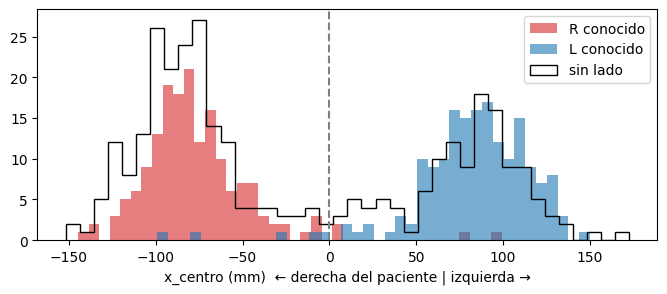

In [11]:
#  — ¿La posición x de la rodilla (coordenadas del paciente) predice el lado?
elegidas_v2["lado"] = elegidas_v2["lado"].replace({"RIGHT": "R", "LEFT": "L"})

def x_centro(fila):
    """Posición x media (mm) de todos los cortes de la serie. En DICOM, +x = izquierda del paciente."""
    xs = [float(pydicom.dcmread(a, stop_before_pixels=True,
                                specific_tags=["ImagePositionPatient"]).ImagePositionPatient[0])
          for a in carpeta_serie(fila).glob("*.dcm")]
    return float(np.mean(xs))

elegidas_v2["x_centro"] = [x_centro(f) for f in elegidas_v2.itertuples()]

con = elegidas_v2[elegidas_v2["lado"].notna()]
sin = elegidas_v2[elegidas_v2["lado"].isna()]
print("x_centro (mm) según el lado conocido:")
print(con.groupby("lado")["x_centro"].describe().round(1))

pred = np.where(con["x_centro"] < 0, "R", "L")
print(f"\nRegla 'x < 0 → R': acierto {(pred == con['lado']).mean():.3f} en {len(con)} series con lado conocido")
print(pd.crosstab(con["lado"], pred, rownames=["real"], colnames=["regla"]))
print("\nAcierto por fabricante:")
print(con.assign(ok=(pred == con["lado"])).groupby("fabricante")["ok"].agg(["mean", "size"]).round(3))

print("\nSeries SIN lado: x_centro"); print(sin["x_centro"].describe().round(1))
print("Sin lado con |x| < 20 mm (zona dudosa):", (sin["x_centro"].abs() < 20).sum())

fig, ax = plt.subplots(figsize=(8, 3))
for lado, color in [("R", "tab:red"), ("L", "tab:blue")]:
    ax.hist(con.loc[con.lado == lado, "x_centro"], bins=40, alpha=.6, color=color, label=f"{lado} conocido")
ax.hist(sin["x_centro"], bins=40, histtype="step", color="k", label="sin lado")
ax.axvline(0, color="gray", ls="--"); ax.set_xlabel("x_centro (mm)  ← derecha del paciente | izquierda →")
ax.legend(); plt.show()


### Interpretación  — La posición x de la rodilla predice el lado

**Hipótesis:** en coordenadas DICOM, +x = izquierda del paciente → rodilla derecha con x < 0 e izquierda con x > 0.

**Validación en las 344 series con lado conocido:**
- Dos grupos **claramente separados**: R con mediana **−82 mm**, L con mediana **+86 mm** (≈ 8 cm a cada lado de la
  línea media, la distancia esperable de la rodilla al centro del cuerpo).
- Regla `x < 0 → R`: **acierto 0.974** (335/344). Errores: 5 L con x < 0 y 4 R con x > 0.
- Los técnicos **no centran la rodilla** en el resonador → la posición conserva la información del lado.

**Por fabricante:** Siemens 0.99 (197), Philips 0.98 (107), GE 1.00 (28). Fabricantes pequeños con pocos casos:
GEHC 0.50 (6), Fujifilm 0.80 (5), Hitachi 0/1.

**OJOOOO** Toshiba (41) y Canon (6) no tienen ninguna serie con lado conocido** → en ellos la regla **no está validada**.

**Series sin lado (312):** el histograma muestra los mismos dos grupos (más series a la derecha, mediana −61 mm).
Solo **17 caen en la zona dudosa** (|x| < 20 mm).

**Conclusión:** se usa la regla de x para las 312 series sin lado, con un error esperado de ~2.6 % (≈ 8 series).
Ese error equivale a intercambiar medial y lateral en pocos estudios: ruido de etiqueta pequeño, que se **documenta**.
Los casos dudosos y los fabricantes no validados se revisan visualmente (10.2e).


In [12]:
# — Lado final de las 656 series, con su fuente
x_dice = pd.Series(np.where(elegidas_v2["x_centro"] < 0, "R", "L"), index=elegidas_v2.index)
elegidas_v2["lado_final"]  = elegidas_v2["lado"].fillna(x_dice)
elegidas_v2["lado_fuente"] = np.where(elegidas_v2["lado"].notna(), "dicom/texto", "x")
dudosa = elegidas_v2["lado"].isna() & (elegidas_v2["x_centro"].abs() < 20)
elegidas_v2.loc[dudosa, "lado_fuente"] = "x_dudosa"

print("Fuente del lado:"); print(pd.crosstab(elegidas_v2["lado_fuente"], elegidas_v2["lado_final"], margins=True))
print("\nFuente del lado por split:"); print(pd.crosstab(elegidas_v2["split"], elegidas_v2["lado_fuente"]))
print("\n¿Con o sin lado conocido, por fabricante?")
print(pd.crosstab(elegidas_v2["fabricante"], elegidas_v2["lado"].notna().map({True: "conocido", False: "por x"})))

print("\nLos 9 errores de la regla (lado conocido ≠ lo que dice x):")
print(con.loc[pred != con["lado"], ["lado", "x_centro", "fabricante", "Descripcion", "split"]]
      .round(1).to_string(index=False))


Fuente del lado:
lado_final     L    R  All
lado_fuente               
dicom/texto  174  170  344
x            115  180  295
x_dudosa       8    9   17
All          297  359  656

Fuente del lado por split:
lado_fuente  dicom/texto    x  x_dudosa
split                                  
test                  28   26         2
train                248  219        13
val                   68   50         2

¿Con o sin lado conocido, por fabricante?
lado        conocido  por x
fabricante                 
CANON_MEC          0      6
FUJIFILM           5      0
GE                28    120
GEHC               6      0
HITACHI            1      0
PHILIPS          107     99
SIEMENS          197     46
TOSHIBA            0     41

Los 9 errores de la regla (lado conocido ≠ lo que dice x):
lado  x_centro fabricante                     Descripcion split
   R       4.1       GEHC                Water: SMART FAT train
   L     -99.0    SIEMENS pd_tse_sag   FS_448_2.5mm_p2_s2 train
   L     -26.5    

### Interpretación  — Lado final y análisis de los errores

**Lado final de las 656 series:** 297 L / 359 R.
| Fuente | Series | Fiabilidad |
|---|---|---|
| DICOM / texto | 344 | alta (las dos fuentes nunca se contradicen) |
| Regla x | 295 | ~97 % (validada en las 344 conocidas) |
| Regla x dudosa (\|x\| < 20 mm) | 17 | baja → revisión visual |

- **Gold:** 28 con lado DICOM, 26 por x y 2 dudosos.
- **Fabricantes sin validación:** Toshiba (41) y Canon (6) dependen al 100 % de la regla x sin un solo caso conocido
  → revisión visual de una muestra. GE (120 por x) sí está validado (28/28 correctos).

**Los 9 errores tienen dos patrones distintos:**
1. **x cercana a 0 (5 de 9: 4.1, 6.1, −1.3, −8.8, −26.5 mm)** → GEHC "SMART FAT" (3), Hitachi y Fujifilm.
   Estos centros **sí centran la rodilla** en el resonador, y entonces x no informa. Son errores *esperables* en la
   zona dudosa; el umbral de 20 mm captura 4 de 5 (el de −26.5 queda fuera → valorar ampliar el umbral a 30 mm).
2. **x lejos de 0 (3 de 9: −99, +80, +99 mm)** → la regla y el campo de lateralidad se contradicen con claridad.
   Dos son del **mismo protocolo Siemens** (`pd_tse_sag FS_448_2.5mm_p2_s2`), uno en cada dirección. Causas posibles:
   (a) el campo de lateralidad está mal, o (b) el técnico registró mal la posición del paciente (p. ej. "cabeza
   primero" cuando entró con los pies primero), lo que **invierte el eje x**. No se puede saber cuál de las dos
   fuentes está mal sin mirar la imagen → revisión visual.


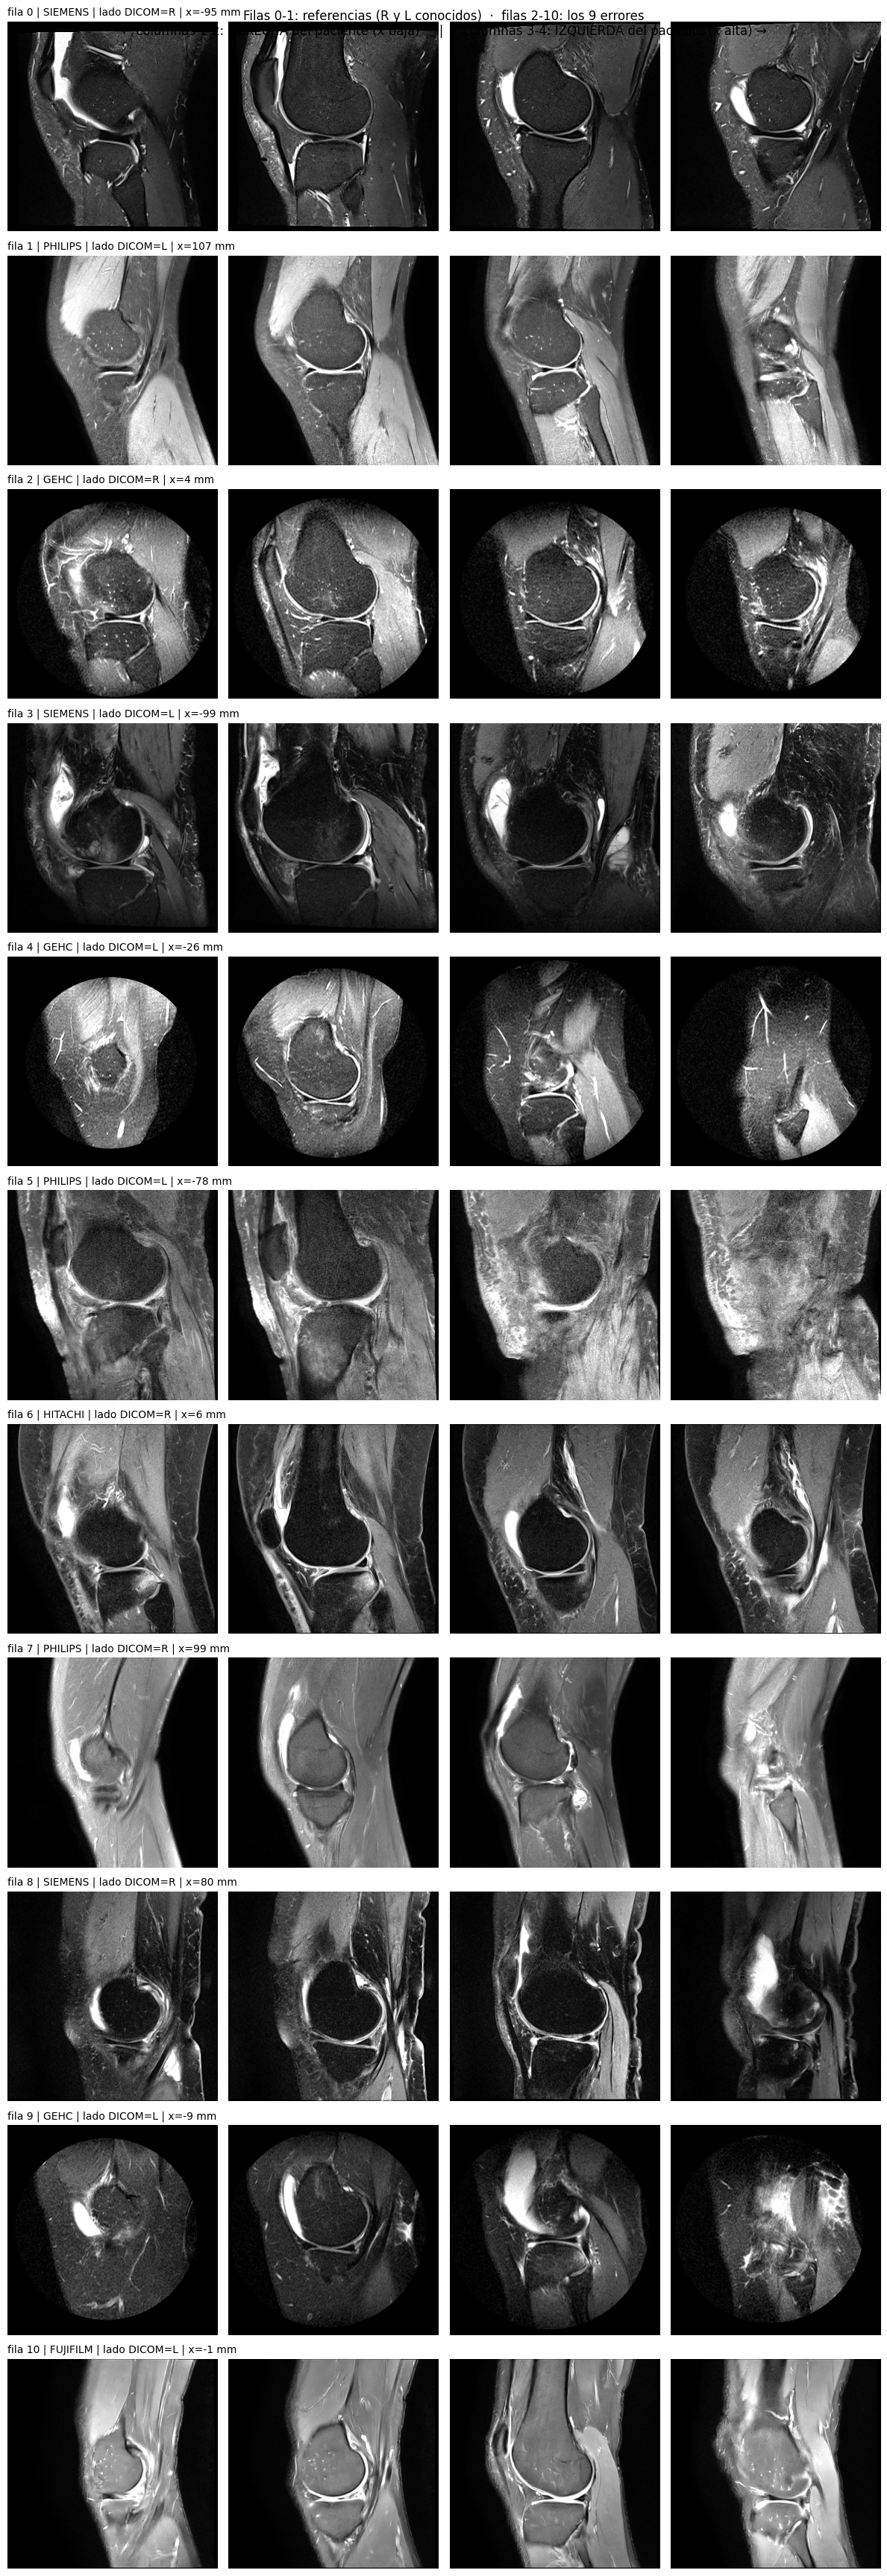

In [13]:
#  — Revisión visual: ¿en qué extremo (x baja o x alta) aparece la cabeza del peroné?
def cortes_extremos(fila, fracs=(0.15, 0.25, 0.75, 0.85)):
    archivos = list(carpeta_serie(fila).glob("*.dcm"))
    xs = [float(pydicom.dcmread(a, stop_before_pixels=True,
                                specific_tags=["ImagePositionPatient"]).ImagePositionPatient[0]) for a in archivos]
    orden = np.argsort(xs)                      # de x baja (derecha del paciente) a x alta (izquierda)
    return [pydicom.dcmread(archivos[orden[round(f * (len(orden) - 1))]]).pixel_array for f in fracs]

def mostrar(filas, titulo):
    fig, ax = plt.subplots(len(filas), 4, figsize=(12, 3.2 * len(filas)))
    for r, (_, f) in enumerate(filas.iterrows()):
        for c, img in enumerate(cortes_extremos(f)):
            ax[r, c].imshow(img, cmap="gray", vmax=np.percentile(img, 99)); ax[r, c].axis("off")
        lado = f.lado if pd.notna(f.lado) else "?"
        ax[r, 0].set_title(f"fila {r} | {f.fabricante} | lado DICOM={lado} | x={f.x_centro:.0f} mm",
                           fontsize=10, loc="left")
    fig.suptitle(f"{titulo}\n← columnas 1-2: DERECHA del paciente (x baja)     |     "
                 f"columnas 3-4: IZQUIERDA del paciente (x alta) →", fontsize=12)
    plt.tight_layout(); plt.show()

ref = pd.concat([con[(con.lado == "R") & (con.x_centro < -80)].sample(1, random_state=0),
                 con[(con.lado == "L") & (con.x_centro > 80)].sample(1, random_state=0)])
errores = con[pred != con["lado"]]
mostrar(pd.concat([ref, errores]), "Filas 0-1: referencias (R y L conocidos)  ·  filas 2-10: los 9 errores")


LLENADO VISUALMENTE PARA IDENTIFICAR DONDE ESTA EL PERONE EN CADA ESTUDIO

In [14]:
#  (registro) — Revisión visual de los 9 errores: ¿en qué columnas está el peroné?
#   "1-2" → peroné en x baja  → rodilla DERECHA (R)
#   "3-4" → peroné en x alta  → rodilla IZQUIERDA (L)
#   "?"   → no se distingue
revision_errores = {2: "1-2", 3: "1-2", 4: "3-4", 5: "1-2", 6: "1-2", 7: "3-4", 8: "3-4", 9: "3-4", 10: "3-4"}

filas_rev = pd.concat([ref, errores]).reset_index(drop=True)
filas_rev["visual"] = filas_rev.index.map(revision_errores).map({"1-2": "R", "3-4": "L"})
filas_rev["x_dice"] = np.where(filas_rev["x_centro"] < 0, "R", "L")
print(filas_rev.loc[2:, ["fabricante", "lado", "x_dice", "visual", "x_centro"]].round(0).to_string())
print("\nLa imagen da la razón a → DICOM:", (filas_rev.loc[2:, "visual"] == filas_rev.loc[2:, "lado"]).sum(),
      "| regla x:", (filas_rev.loc[2:, "visual"] == filas_rev.loc[2:, "x_dice"]).sum(),
      "| sin decidir:", filas_rev.loc[2:, "visual"].isna().sum())


   fabricante lado x_dice visual  x_centro
2        GEHC    R      L      R       4.0
3     SIEMENS    L      R      R     -99.0
4        GEHC    L      R      L     -26.0
5     PHILIPS    L      R      R     -78.0
6     HITACHI    R      L      R       6.0
7     PHILIPS    R      L      L      99.0
8     SIEMENS    R      L      L      80.0
9        GEHC    L      R      L      -9.0
10   FUJIFILM    L      R      L      -1.0

La imagen da la razón a → DICOM: 5 | regla x: 4 | sin decidir: 0


### Interpretación  — Revisión visual de los 9 desacuerdos (peroné = lado lateral)

Método validado con 2 referencias (R → peroné en x baja; L → peroné en x alta).

| Grupo | Filas | \|x\| | La imagen da la razón a… |
|---|---|---|---|
| **x cerca de 0** | 2, 4, 6, 9, 10 (GEHC ×3, Hitachi, Fujifilm) | 1 – 26 mm | **DICOM** (5 de 5) |
| **x lejos de 0** | 3, 5, 7, 8 (Siemens ×2, Philips ×2) | 78 – 99 mm | **regla x** (4 de 5… 4 de 4) |

**Conclusiones:**
1. **Cerca de 0, la x no informa:** esos centros colocan la rodilla en el centro del resonador → manda el DICOM.
2. **Lejos de 0, la x es más fiable que el propio campo DICOM:** en los 4 casos lejanos, el campo de lateralidad
   estaba **equivocado** (el técnico escribió el lado incorrecto o reutilizó un protocolo con "RT" en el nombre;
   dos casos son del mismo protocolo Siemens). Es decir, **≈ 1.2 % de los lados "conocidos" (4/344) estaban mal**.
3. Entre los 26.5 y los 78 mm no hubo ningún error → hay un umbral natural en esa franja.

**Regla de lateralidad v2:**
- \|x\| ≥ 40 mm → **lado según x** (aunque contradiga al DICOM).
- \|x\| < 40 mm y hay DICOM/texto → **lado según DICOM**.
- \|x\| < 40 mm y no hay DICOM → **revisión visual** (peroné).


In [15]:
# Lateralidad v2: lejos de 0 manda x; cerca de 0 manda DICOM; cerca de 0 sin DICOM → revisión visual
UMBRAL = 40
lejos  = elegidas_v2["x_centro"].abs() >= UMBRAL
x_dice = pd.Series(np.where(elegidas_v2["x_centro"] < 0, "R", "L"), index=elegidas_v2.index)

elegidas_v2["lado_final"]  = x_dice.where(lejos, elegidas_v2["lado"])        # NaN = falta revisar
elegidas_v2["lado_fuente"] = np.select([lejos, elegidas_v2["lado"].notna()], ["x", "dicom/texto"], "revisar")

print("Fuente del lado por split:")
print(pd.crosstab(elegidas_v2["lado_fuente"], elegidas_v2["split"], margins=True))
corregidos = elegidas_v2[lejos & elegidas_v2["lado"].notna() & (elegidas_v2["lado"] != x_dice)]
print(f"\nLados DICOM corregidos por x (|x| ≥ {UMBRAL}): {len(corregidos)}")
print(corregidos[["split", "fabricante", "lado", "lado_final", "x_centro"]].round(0).to_string())
print("\nSeries por x, por fabricante (Toshiba y Canon aún sin validar):")
print(elegidas_v2.loc[lejos, "fabricante"].value_counts())

# Lote para revisión visual: las que faltan + muestra de validación de Toshiba y Canon
lote = pd.concat([elegidas_v2[elegidas_v2["lado_fuente"] == "revisar"],
                  elegidas_v2[lejos & (elegidas_v2.fabricante == "TOSHIBA")].sample(4, random_state=0),
                  elegidas_v2[lejos & (elegidas_v2.fabricante == "CANON_MEC")].sample(2, random_state=0)]
                ).reset_index(drop=True)
print(f"\nLote de revisión visual: {len(lote)} series "
      f"({(lote.lado_fuente == 'revisar').sum()} sin lado + 6 de validación Toshiba/Canon)")

prioridad = np.where(lote["lado_fuente"] == "x", 1, lote["split"].map({"test": 0, "val": 1, "train": 2}))
lote = lote.assign(prio=prioridad).sort_values("prio", kind="stable").reset_index(drop=True)
print(lote.groupby("prio").size().rename({0: "test", 1: "val + validación Toshiba/Canon", 2: "train (opcional)"}))


Fuente del lado por split:
split        test  train  val  All
lado_fuente                       
dicom/texto     3     13    6   22
revisar         4     26    7   37
x              49    441  107  597
All            56    480  120  656

Lados DICOM corregidos por x (|x| ≥ 40): 4
     split fabricante lado lado_final  x_centro
124  train    SIEMENS    L          R     -99.0
375  train    PHILIPS    L          R     -78.0
493    val    PHILIPS    R          L      99.0
509  train    SIEMENS    R          L      80.0

Series por x, por fabricante (Toshiba y Canon aún sin validar):
fabricante
SIEMENS      235
PHILIPS      205
GE           127
TOSHIBA       24
CANON_MEC      6
Name: count, dtype: int64

Lote de revisión visual: 43 series (37 sin lado + 6 de validación Toshiba/Canon)
prio
test                               4
val + validación Toshiba/Canon    13
train (opcional)                  26
dtype: int64


### Interpretación — Lateralidad v2 aplicada

| Fuente | test | train | val | Total |
|---|---|---|---|---|
| x (\|x\| ≥ 40 mm) | 49 | 441 | 107 | **597 (91 %)** |
| DICOM/texto (\|x\| < 40 mm) | 3 | 13 | 6 | 22 |
| revisión visual (\|x\| < 40 mm, sin DICOM) | 4 | 26 | 7 | **37** |

- La regla x decide el **91 %** de las series.
- **Lados DICOM corregidos por x: exactamente los 4 que se confirmaron visualmente** (2 Siemens, 2 Philips): la regla
  v2 no contradice al DICOM en ningún caso que no hayamos comprobado con la imagen.
- **Toshiba:** solo 24 de 41 series están lejos de 0 → este fabricante (o sus centros) suele centrar la rodilla;
  sus 17 series restantes están en el lote de revisión.
- Se revisan visualmente **43 series**: las 37 que no se pueden decidir + 6 de validación (4 Toshiba, 2 Canon),
  para comprobar que esos fabricantes guardan bien las coordenadas.


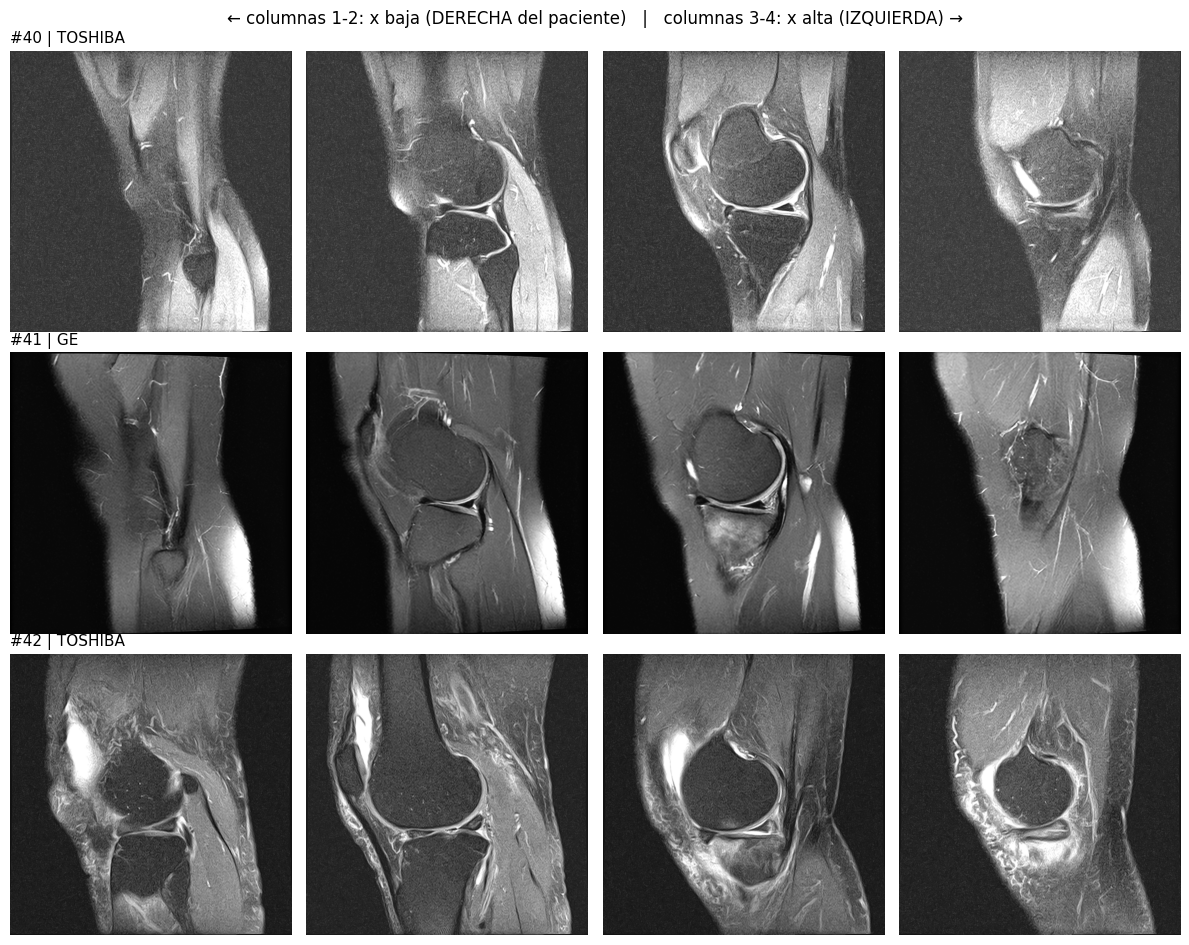

In [16]:
# — Revisión visual CIEGA del lote. Cambia TANDA = 0, 1, 2, 3, 4, 5 y vuelve a ejecutar la celda
def mostrar_ciego(filas):
    fig, ax = plt.subplots(len(filas), 4, figsize=(12, 3.2 * len(filas)), squeeze=False)
    for r, (i, f) in enumerate(filas.iterrows()):
        for c, img in enumerate(cortes_extremos(f)):
            ax[r, c].imshow(img, cmap="gray", vmax=np.percentile(img, 99)); ax[r, c].axis("off")
        ax[r, 0].set_title(f"#{i} | {f.fabricante}", fontsize=11, loc="left")
    fig.suptitle("← columnas 1-2: x baja (DERECHA del paciente)   |   columnas 3-4: x alta (IZQUIERDA) →",
                 fontsize=12)
    plt.tight_layout(); plt.show()

TANDA = 5
mostrar_ciego(lote.iloc[8 * TANDA: 8 * TANDA + 8])


In [17]:
# 10.2g (registro) — Revisión visual ciega: "1-2" → R · "3-4" → L · "?" → no se distingue
revision_lote = {
     0: "1-2",  1: "3-4",  2: "1-2",  3: "1-2",  4: "3-4",  5: "3-4",  6: "1-2",  7: "1-2",
     8: "1-2",  9: "3-4", 10: "3-4", 11: "3-4", 12: "3-4", 13: "1-2", 14: "1-2", 15: "3-4",
    16: "1-2", 17: "1-2", 18: "3-4", 19: "?", 20: "1-2", 21: "3-4", 22: "3-4", 23: "1-2",
    24: "1-2", 25: "?", 26: "3-4", 27: "3-4", 28: "3-4", 29: "1-2", 30: "3-4", 31: "3-4",
    32: "3-4", 33: "1-2", 34: "3-4", 35: "3-4", 36: "3-4", 37: "3-4", 38: "3-4", 39: "1-2",
    40: "1-2", 41: "1-2", 42: "1-2"}

lote["visual"] = lote.index.map(revision_lote).map({"1-2": "R", "3-4": "L"})
lote["x_dice"] = np.where(lote["x_centro"] < 0, "R", "L")

valid = lote[lote["lado_fuente"] == "x"]                      # las 6 de Toshiba / Canon
print("Validación Toshiba/Canon — la imagen coincide con x:",
      (valid["visual"] == valid["x_dice"]).sum(), "de", valid["visual"].notna().sum())
dud = lote[lote["lado_fuente"] == "revisar"]                  # las 37 cercanas a 0 sin DICOM
print("Cercanas a 0 — la imagen coincide con x:",
      (dud["visual"] == dud["x_dice"]).sum(), "de", dud["visual"].notna().sum(), "(esperamos que x falle a menudo)")

nuevos = dud.set_index("SeriesInstanceUID")["visual"].dropna()
m = elegidas_v2["SeriesInstanceUID"].map(nuevos)
elegidas_v2.loc[m.notna(), ["lado_final", "lado_fuente"]] = list(zip(m[m.notna()], ["visual"] * m.notna().sum()))
print("\nFuente final del lado:"); print(pd.crosstab(elegidas_v2["lado_fuente"], elegidas_v2["split"], margins=True))
print("Series aún sin lado:", elegidas_v2["lado_final"].isna().sum())

falta = elegidas_v2["lado_final"].isna() & (elegidas_v2["split"] == "train")
elegidas_v2.loc[falta, "lado_final"]  = np.where(elegidas_v2.loc[falta, "x_centro"] < 0, "R", "L")
elegidas_v2.loc[falta, "lado_fuente"] = "x_dudosa"
print("\nTras completar train con x_dudosa:")
print(pd.crosstab(elegidas_v2["lado_fuente"], elegidas_v2["split"], margins=True))
print("Series aún sin lado (deberían ser 0):", elegidas_v2["lado_final"].isna().sum())


Validación Toshiba/Canon — la imagen coincide con x: 6 de 6
Cercanas a 0 — la imagen coincide con x: 31 de 35 (esperamos que x falle a menudo)

Fuente final del lado:
split        test  train  val  All
lado_fuente                       
dicom/texto     3     13    6   22
revisar         0      2    0    2
visual          4     24    7   35
x              49    441  107  597
All            56    480  120  656
Series aún sin lado: 2

Tras completar train con x_dudosa:
split        test  train  val  All
lado_fuente                       
dicom/texto     3     13    6   22
visual          4     24    7   35
x              49    441  107  597
x_dudosa        0      2    0    2
All            56    480  120  656
Series aún sin lado (deberían ser 0): 0


### Interpretación — Revisión visual ciega y lateralidad final

- **Validación Toshiba/Canon: 6 de 6** → estos fabricantes también guardan bien las coordenadas; la regla x queda
  validada para los 30 estudios de Toshiba/Canon que dependen de ella.
- **Series cercanas a 0 (|x| < 40 mm) sin DICOM:** la imagen coincidió con x en **31 de 35 (89 %)** → la x casi siempre
  acierta incluso en esa zona, pero falló en 4, que la revisión visual corrigió. El umbral de 40 mm es conservador.
- 2 series de train no se distinguieron visualmente → lado por x, marcadas como `x_dudosa`.

**Lateralidad final de las 656 series:**
| Fuente | test | train | val | Total |
|---|---|---|---|---|
| x (\|x\| ≥ 40 mm) | 49 | 441 | 107 | 597 |
| visual (peroné, revisión ciega) | 4 | 24 | 7 | 35 |
| DICOM/texto | 3 | 13 | 6 | 22 |
| x_dudosa | 0 | 2 | 0 | 2 |

**Los gold (test) tienen todos un lado fiable** (x lejos de 0, DICOM o revisión visual).

###  Resumen de la lateralidad (para el informe)
1. El campo DICOM `Laterality` falta en el 48 % de las series y está **equivocado en ~1.2 %** de las que lo tienen.
2. La posición x de la rodilla (coordenadas del paciente; +x = izquierda) predice el lado con un 97.4 % de acierto, y
   lejos del centro (\|x\| ≥ 40 mm) es **más fiable que el propio DICOM** (4 de 4 desacuerdos confirmados por imagen).
3. Los casos ambiguos se resolvieron con **revisión visual ciega** de la cabeza del peroné (marcador del lado lateral).
4. **Por qué importa:** el lado define qué extremo del volumen sagital es medial y cuál lateral; sin él la CNN no podría
   distinguir Medial/Lateral Meniscus ni Medial/Lateral OA.


In [18]:
# 10.2g (guardar) — series elegidas + lateralidad
cols = ["StudyInstanceUID", "SeriesInstanceUID", "split", "contraste", "n_cortes", "SerieN", "TE",
        "Grosor", "Pixel", "Filas", "Cols", "fabricante", "x_centro", "lado_final", "lado_fuente"]
elegidas_v2[cols].to_csv(OUT / "series_elegidas.csv", index=False)
print(pd.read_csv(OUT / "series_elegidas.csv").shape)
print(elegidas_v2["lado_final"].value_counts())


(656, 15)
lado_final
R    359
L    297
Name: count, dtype: int64


n_cortes  fabricante  contraste  Grosor
144       SIEMENS     DP         0.89       7
320       PHILIPS     DP         0.80       5
                                 0.80      10
Name: series, dtype: int64

=== 144 cortes | Siemens Healthineers | pd_spc_rst_fs_sag_iso R | split=train
MRAcquisitionType: 3D | Grosor: 0.89 | Píxel: ['0.885417', '0.885417'] | Matriz: 192 x 192
Posiciones distintas: 144 de 144 | Distancia entre cortes (mm): [0.89] | Cobertura: 127.3 mm


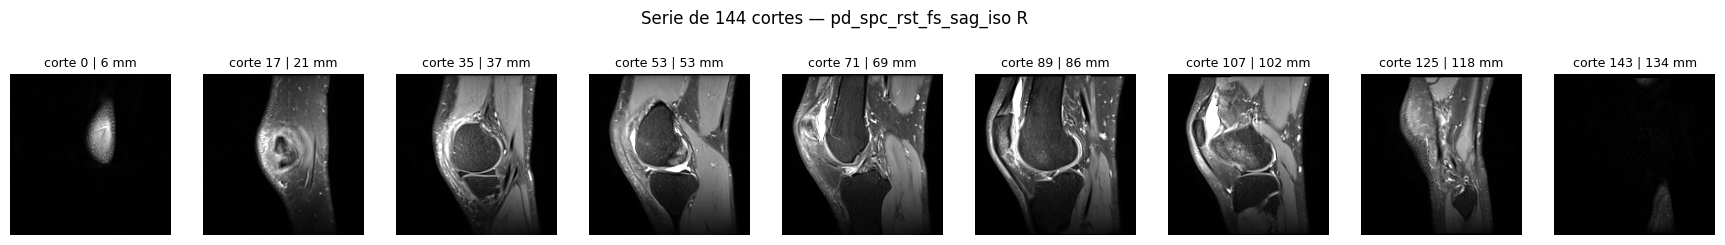


=== 320 cortes | Philips Medical Systems | SAG 3D_VIEW_PD_SPAIR_HR L | split=train
MRAcquisitionType: 3D | Grosor: 0.80000001192092 | Píxel: ['0.28145694732666', '0.28145694732666'] | Matriz: 640 x 640
Posiciones distintas: 320 de 320 | Distancia entre cortes (mm): [0.4] | Cobertura: 127.6 mm


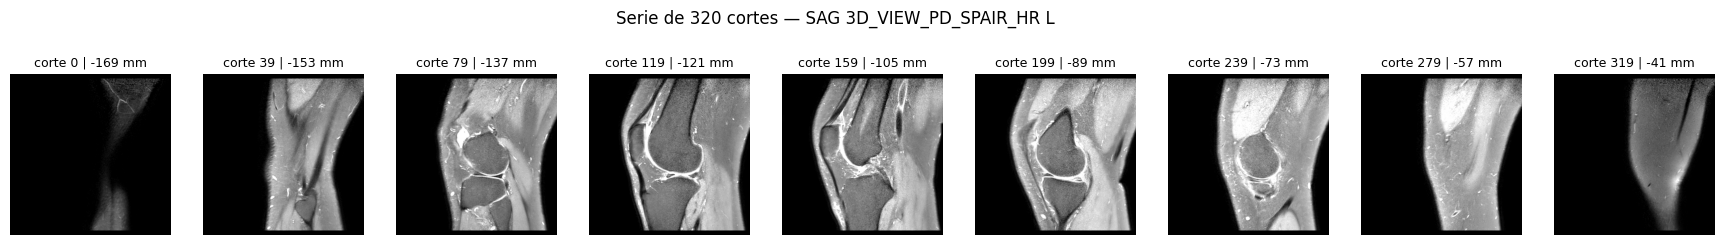

In [19]:
#  — Las series de 144 y 320 cortes: ¿una pila 3D fina o varias pilas?
print(elegidas_v2.loc[elegidas_v2.n_cortes > 60]
      .groupby(["n_cortes", "fabricante", "contraste", "Grosor"]).size().rename("series"))

for n in (144, 320):
    f = elegidas_v2[elegidas_v2.n_cortes == n].iloc[0]
    cortes, pos = leer_serie(f)
    d = cortes[0]
    print(f"\n=== {n} cortes | {d.get('Manufacturer')} | {d.get('SeriesDescription')} | split={f.split}")
    print("MRAcquisitionType:", d.get("MRAcquisitionType"), "| Grosor:", d.get("SliceThickness"),
          "| Píxel:", list(d.get("PixelSpacing")), "| Matriz:", d.Rows, "x", d.Columns)
    print("Posiciones distintas:", len(np.unique(np.round(pos, 2))), "de", len(pos),
          "| Distancia entre cortes (mm):", np.unique(np.round(np.diff(pos), 2))[:8],
          "| Cobertura:", round(pos[-1] - pos[0], 1), "mm")
    vol = np.stack([c.pixel_array for c in cortes]).astype(np.float32)
    idx = np.linspace(0, len(cortes) - 1, 9).astype(int)
    fig, ax = plt.subplots(1, 9, figsize=(22, 3))
    for a, i in zip(ax, idx):
        a.imshow(vol[i], cmap="gray", vmax=np.percentile(vol, 99))
        a.set_title(f"corte {i} | {pos[i]:.0f} mm", fontsize=9); a.axis("off")
    plt.suptitle(f"Serie de {n} cortes — {d.get('SeriesDescription')}"); plt.show()


### Interpretación — Las series de 144 y 320 cortes son adquisiciones 3D

| | 144 cortes | 320 cortes |
|---|---|---|
| Fabricante / protocolo | Siemens `pd_spc_rst_fs_sag_iso` (SPACE) | Philips `SAG 3D_VIEW_PD_SPAIR_HR` |
| Series en el dataset | 7 | 15 |
| `MRAcquisitionType` | **3D** | **3D** |
| Vóxel | **0.89 × 0.89 × 0.89 mm** (isotrópico) | 0.28 × 0.28 mm en el plano, grosor 0.8 mm |
| Distancia entre cortes | 0.89 mm | **0.4 mm** (cortes de 0.8 mm solapados a la mitad) |
| Matriz | 192 × 192 (menos detalle en el plano) | 640 × 640 |
| Cobertura | 127 mm | 128 mm |

- **Son una sola pila** (144 de 144 y 320 de 320 posiciones distintas): no hay ecos ni pilas mezclados → se pueden
  tratar como las 2D, solo que con cortes mucho más finos y juntos.
- Las 22 son **DP**, de solo 2 protocolos.
- **Cubren más que una 2D** (~127 mm frente a ~100 mm de la serie de 29 cortes): los extremos son casi vacíos
  (cortes 0 y 143/319).


   Si se eligieran los cortes **por fracción del índice** (p. ej. "el corte al 25 %"), en una 3D caería en otra
  anatomía que en una 2D → **hay que elegir los cortes por posición física (mm)**, no por índice.
- Un corte de 0.4–0.9 mm tiene **menos señal y más ruido** que uno de 3–4 mm → conviene **promediar los cortes finos
  dentro de una "lámina" de ~3.5 mm** para que se parezcan a un corte 2D (reformateo de lámina gruesa).


## Decisiones del preprocesamiento

Resumen de lo aprendido en el 10.1–10.2 y su traducción en decisiones:

| # | Problema observado | Decisión |
|---|---|---|
| 1 | Los archivos `.dcm` no vienen en orden anatómico | Ordenar los cortes por posición física (`ImagePositionPatient` proyectada sobre la normal al corte) |
| 2 | Rodilla derecha e izquierda invierten el orden medial ↔ lateral | Orientar con `lado_final`: **canal 0 = siempre el lado medial** |
| 3 | Las 2D cubren ~100 mm y las 3D ~127 mm | Elegir cortes **por posición en mm respecto al centro del volumen**, no por índice |
| 4 | Los cortes 3D (0.4–0.9 mm) son finos y ruidosos | Cada corte de salida = **promedio de los cortes dentro de ±1.75 mm** (lámina de ~3.5 mm, como una 2D) |
| 5 | La RM no tiene unidades fijas (cada equipo usa su escala) | Por volumen: recortar entre los percentiles **0.5 y 99.5** y llevar a **[0, 1]** |
| 6 | Matrices de 192² a 1024² según el centro | Redimensionar a **256 × 256** |
| 7 | ¿Cuántos cortes usar? | Guardar **15 cortes cada 4 mm (−28 … +28 mm)** en `float16` (~1.3 GB) |

**Por qué 15 cortes de −28 a +28 mm:** los compartimentos están a unos ±25 mm del centro y la escotadura (LCA/LCP) en el
centro → el rango cubre cóndilo medial → escotadura → cóndilo lateral. Guardar 15 deja abiertas todas las opciones
sin volver a leer los DICOM:
- CNN desde cero: 7 cortes como canales (2.5D).
- Transfer learning (3 canales de ImageNet): 3 cortes, o cada corte por la red y combinar.
- Ablación: 1 corte central (2D) frente a 7 o 15 (2.5D).

**Limitación (declarar en el informe):** se supone que el centro del volumen ≈ el centro de la rodilla. Una serie
descentrada desplaza los cortes algunos mm; es tolerable con un paso de 4 mm y aumento de datos (desplazamientos
pequeños), y se verificará visualmente en el 10.3.

**Archivo de salida de este notebook:** `series_elegidas.csv` (656 series, una por estudio): split, contraste, cortes,
TE, grosor, píxel, matriz, fabricante, `x_centro`, `lado_final`, `lado_fuente`.
